<function matplotlib.pyplot.show(close=None, block=None)>

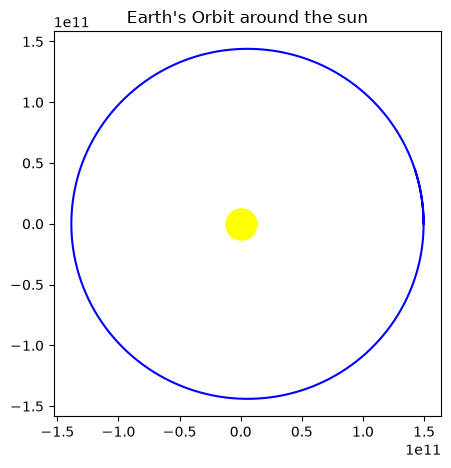

In [1]:
import numpy as np 
import matplotlib.pyplot as plt

tmax = 31449600
dt = 86400
N = int(tmax/dt)
r0 = np.array([149.6e9,0.0])
v0 = np.array([0,29208.36397])
G = 6.67348e-11
M = 1.989e30

def acceleration(r):
    return (-G*M*(r))/((np.sqrt(((r[0])**2)+((r[1])**2)))**3)

def verlet(r0, v0, dt, N):
    v = np.zeros((N,2))
    r = np.zeros((N,2))   
    r[0] = r0
    v[0] = v0
    
    for i in range(0,N-1):
        r[i+1] = r[i] + v[i]*dt + (1/2)*acceleration(r[i])*(dt**2)
        v[i+1] = v[i] + (1/2)*(acceleration(r[i])+acceleration(r[i+1]))*dt
        
    return r, v 

position, velocity = verlet(r0, v0, dt, N)

plt.figure(figsize=(5,5))
x_values = position[:, 0]
y_values = position[:, 1]
plt.plot(x_values,y_values, "b-")
plt.scatter(0,0,color="yellow",s=500)
plt.title("Earth's Orbit around the sun")
plt.show


In [2]:
G = 6.67348e-11
M = 1.989e30
R = 149.6e9
m = 5.972e24

v0 = np.array([0, 29800])  #tangential initial velocity

In [4]:

r = np.zeros((N + 1, 2))
v = np.zeros((N + 1, 2))

r[0] = r0
v[0] = np.array([0, 29800])

# Eq.5 and Eq.6
def a(rk):
    return (-(6.67348e-11)*(1.989e30)*(rk))/((np.sqrt(((rk[0])**2)+((rk[1])**2)))**3)
for k in range(N):
    r[k+1] = r[k] + v[k]*dt + (1/2)*a(r[k])*(dt**2)
    v[k+1] = v[k] + (1/2)*(a(r[k])+a(r[k+1]))*dt

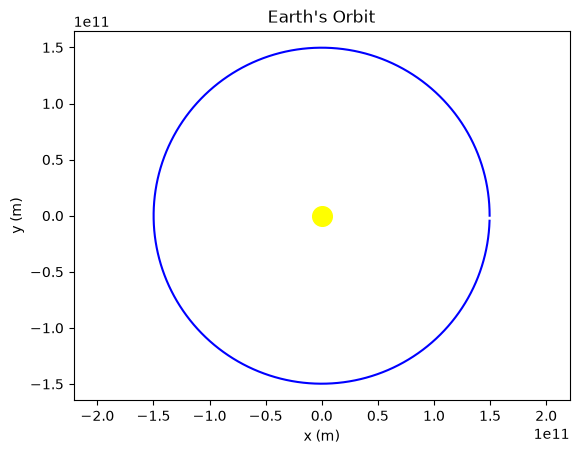

In [5]:
x = r[:, 0]
y = r[:, 1]

plt.plot(x,y, label = "Earth's orbit", color = "blue")

plt.scatter(0,0, label="Sun", s=200, color="yellow")

plt.title("Earth's Orbit")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.axis("equal")
plt.show()

In [9]:
kinetic = np.zeros(N)
potential = np.zeros(N)
total = np.zeros(N)

for i in range(N):
    kinetic[i] = (1/2)*m*(v[i][0]**2 + v[i][1]**2)
    potential[i] = -G*M*m/(np.sqrt(r[i][0]**2 + r[i][1]**2))
    total[i] =  kinetic[i] + potential[i]

In [10]:
energy = np.zeros(N)

# Eq.2
for i in range(N):
    energy[i] = (1/2)*m*(v[i][0]**2+v[i][1]**2) - G*m*M/(np.sqrt(v[i][0]**2+v[i][1]**2))

In [7]:
energy

array([-2.66005513e+40, -2.66005550e+40, -2.66005662e+40, -2.66005847e+40,
       -2.66006106e+40, -2.66006439e+40, -2.66006846e+40, -2.66007327e+40,
       -2.66007881e+40, -2.66008509e+40, -2.66009210e+40, -2.66009984e+40,
       -2.66010831e+40, -2.66011750e+40, -2.66012742e+40, -2.66013806e+40,
       -2.66014941e+40, -2.66016148e+40, -2.66017425e+40, -2.66018773e+40,
       -2.66020192e+40, -2.66021680e+40, -2.66023237e+40, -2.66024864e+40,
       -2.66026559e+40, -2.66028321e+40, -2.66030151e+40, -2.66032048e+40,
       -2.66034011e+40, -2.66036040e+40, -2.66038134e+40, -2.66040292e+40,
       -2.66042514e+40, -2.66044800e+40, -2.66047147e+40, -2.66049557e+40,
       -2.66052028e+40, -2.66054559e+40, -2.66057149e+40, -2.66059799e+40,
       -2.66062507e+40, -2.66065271e+40, -2.66068093e+40, -2.66070969e+40,
       -2.66073901e+40, -2.66076887e+40, -2.66079925e+40, -2.66083016e+40,
       -2.66086157e+40, -2.66089349e+40, -2.66092591e+40, -2.66095881e+40,
       -2.66099218e+40, -

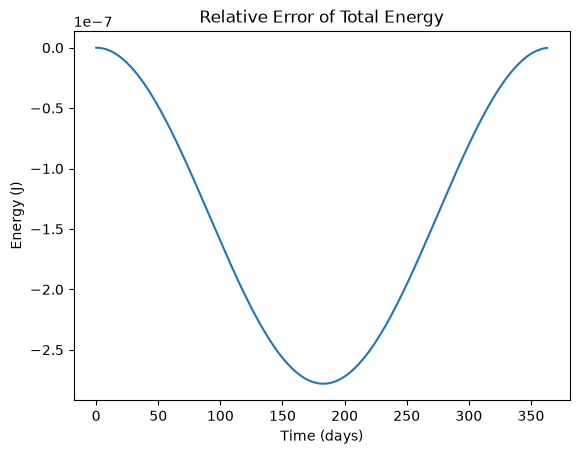

In [12]:
plt.plot(range(N), (total-total[0])/total[0])

plt.xlabel("Time (days)")
plt.ylabel("Energy (J)")
plt.title("Relative Error of Total Energy")
plt.show()

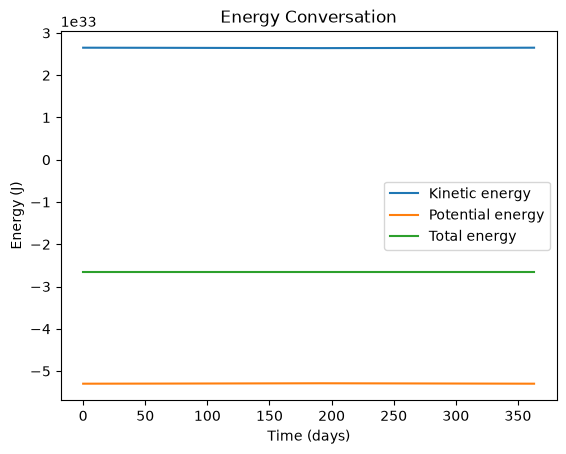

In [13]:
plt.plot(range(N), kinetic, label="Kinetic energy")
plt.plot(range(N), potential, label="Potential energy")
plt.plot(range(N), total, label="Total energy")

plt.xlabel("Time (days)")
plt.ylabel("Energy (J)")
plt.title("Energy Conversation")
plt.legend()
plt.show()

Circular motion is $$F = mv^2/r.$$
The universal gravitational equation is $$F = \frac{GMm}{R^2}.$$
Assume that the orbit is circular, the centripetal force is provided by gravity, that is $$\frac{GMm}{R^2} = \frac{mv^2}{R}.$$
Hence, $$v = \sqrt{\frac{GM}{R}}.$$

In [ ]:
v0_theoretical = np.sqrt(G*M/R)
print("Theoretical initial velocity is", v0_theoretical,"m/s")

Theoretical initial velocity is 29787.069342249833 m/s


In [ ]:
1

1